## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Noah Weinstein

**Date:** 10/12/26


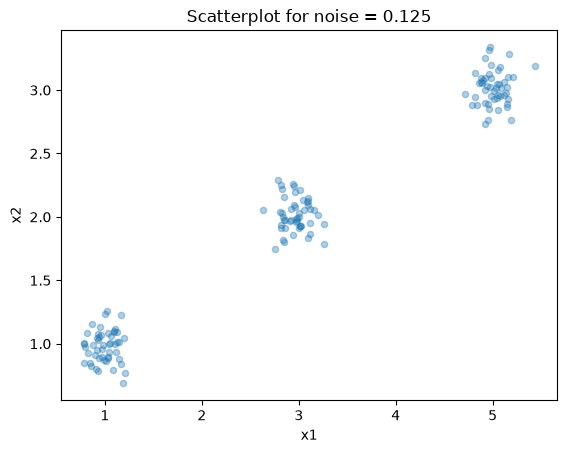

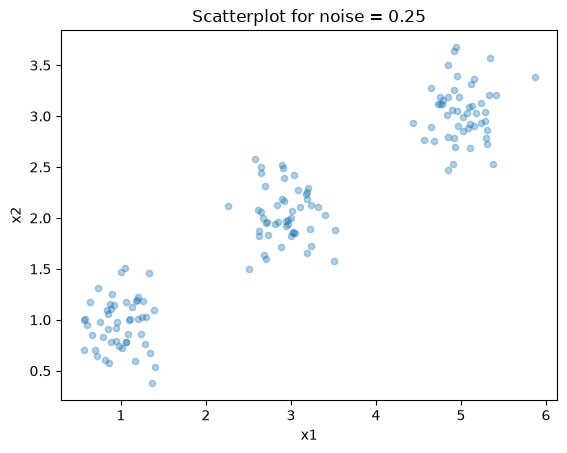

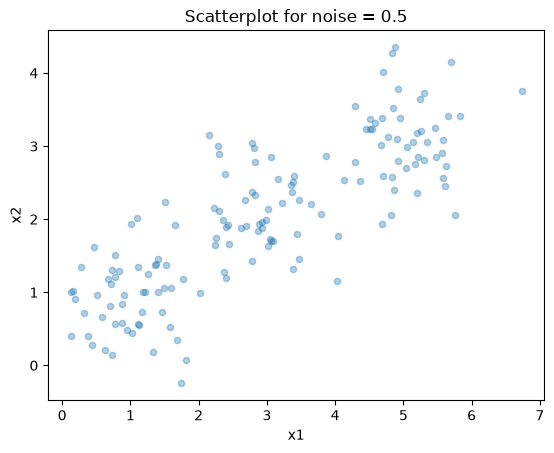

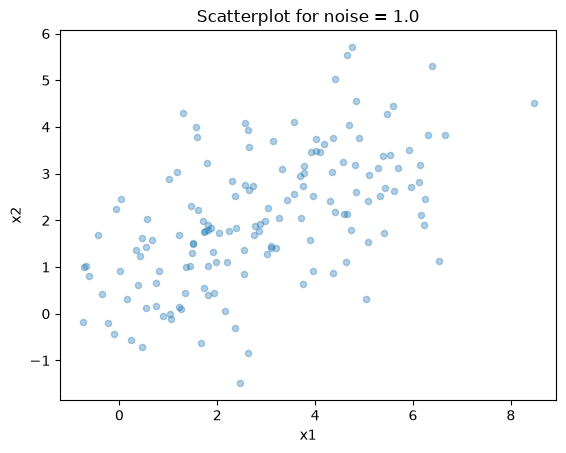

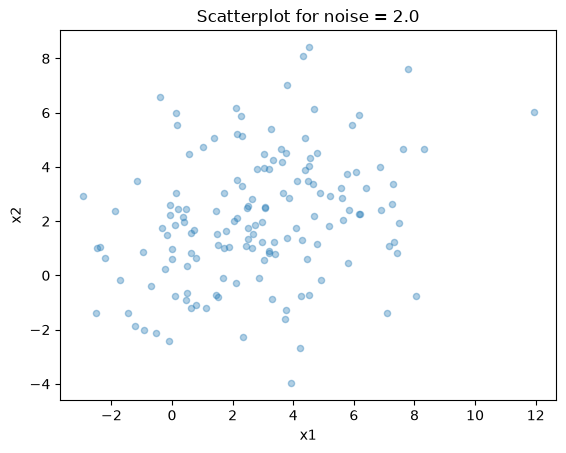

In [1]:
# Your Phase 1 solution to the problem goes here.
#Q1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#Part 2
import matplotlib.pyplot as plt 

df0_125.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 0.125")
plt.show()

df0_25.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 0.25")
plt.show()

df0_5.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 0.5")
plt.show()

df1_0.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 1.0")
plt.show()

df2_0.plot.scatter(x = 0, y = 1, alpha = 0.35)
plt.title("Scatterplot for noise = 2.0")
plt.show()

#Visually, as noise increases, the spread of the points from their original clusters increases. 
#By spread = 0.5, you can't really differentiate between the clusters but can still see the line they
#originally fell on, but at 1.0 and 2.0 the data became much less patterned. 

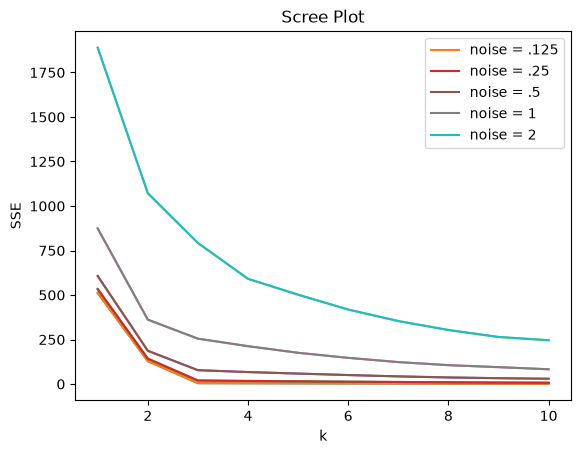

In [ ]:
#Q1 Part 3 (new cell so I don't have to keep scrolling past the scatterplots)

import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans

datasets = {".125": df0_125, ".25": df0_25, ".5": df0_5, "1": df1_0, "2": df2_0}
ks = np.arange(1, 11)
ax = None

for name, dataset in datasets.items():
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(dataset[["x1", "x2"]]).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

    ax = sns.lineplot(x=ks, y=SSE, label=f"noise = {name}", ax=ax)


# I plotted them all together to not have to worry about scaling issues. The level of noise pretty clearly affects the rigidity of the 
# elbow of the scree plot, in a really intuitive manner. The noisier model is, the harder it is to find a harsh elbow and thus
# to difinitively find a value for k. 

# Adding onto that and touching on Q4, the elbow is the point on the Scree plot where the slope of SSE vs k drops the most. The slope
# is pretty much the rate of change of SSE with respect to k, so it's basically finding the point where increasing k further matters
# less and less to the change in SSE. In this situation, when the data isn't noisy and is pretty cleanly centered around its cluster
# points, it makes sense that we'd have a clear elbow at some value k, since the data clearly favors that number of groups. As the data
# gets up to higher noise levels and spreads out like we saw in the scatterplots, there are less clear clusters, and therefore k is less clear. 

(148, 7)


index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
1          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   
2        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
3          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5506.0   30.0  2020.0  ...                       0.048819  0.114776   
1        4656.0    6.0  2020.0  ...                       0.164503  0.225050   
2        5880.0  111.0  2020.0  ...                       0.083508  0.303027   
3        5540.0    1.0  2020.0  ...                       0.081976  0.081976   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858  

[4 rows x 48 columns]

,Country
5540,United States of America


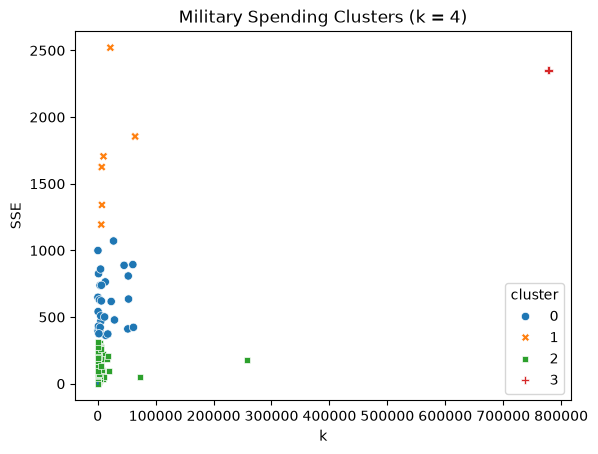

In [18]:
#Q2
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans

df_raw = pd.read_csv("data/SIPRI Military Expenditure Database.csv")

df = df_raw[df_raw["Year"] == 2020].dropna().copy()
print(df.shape)
# No, I don't think anything further is required. I also have 148 countries, and I think it's fine as is. The only thing I would flag
# is perhaps the fact that the index values aren't totally lined up, but it doesn't really matter for the scope of what we're doing.

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])


ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

#Seems like the elbow is at 4

model = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_
ax = sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    style="cluster",
    palette="tab10",
)
placeholder_variable = ax.set(title="Military Spending Clusters (k = 4)") # placeholder so it doesn't output random stuff

#Now, the describe table

display(df.groupby("cluster").describe())
#Find the US

df.loc[df["Country"].str.contains("United States"), ["Country", "cluster"]]
df.loc[df["cluster"] == 3, ["Country"]]


#I notice that the clusters are very uneven in size -- some have as low as 1 and 6, while the largest has 111. The spending per capita is also quite varied.
# The united states is in group 3, the largest one.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]